# 06 · Retention playbook: who to contact, and is it worth it?

**Pipeline:** bronze → silver → gold features → churn model → ARR forecast → **retention playbook**

Expected ARR saved by contacting an account = *save rate* × P(churn within 12 months) × ARR. Contacting costs a
fixed amount per account (CSM time + any incentive). Rank accounts, walk down the list, and stop
where the next account costs more than it is expected to save.

**Assumptions (edit in `revenue_pipeline/config.py`):** outreach cost **$400 per account**;
outreach prevents **25%** of the churn it targets. Both are guesses - the sensitivity grid below
shows how the plan changes if they are wrong, and in practice the save rate should be measured
with a holdout (contact a random half of the target list, compare churn).

Only first-year ARR is counted, so the value of a save is understated.

In [1]:
%pip install -q -r ../requirements.txt

In [2]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
from revenue_pipeline import config, spark_utils

spark = spark_utils.get_spark()
print(f"Spark {spark.version} | schema: {config.SCHEMA} | Databricks: {spark_utils.on_databricks()}")

Spark 3.5.3 | schema: revenue_forecasting | Databricks: False


In [3]:
import matplotlib.pyplot as plt
from revenue_pipeline import retention, charts

charts.apply_style()
risk = spark.table("gold_revenue_risk").toPandas()
curve = retention.targeting_curve(risk)
plan = retention.best_plan(curve)
print(plan.round(2).to_string(index=False))

                strategy  accounts_contacted  expected_arr_saved  outreach_cost  net_value   roi
ARR at risk (prob x ARR)                 431           259424.55       172400.0   87024.55  0.50
             Largest ARR                 710           291147.03       284000.0    7147.03  0.03
       Churn probability                   1              155.95          400.0    -244.05 -0.61
                  Random                   1               67.15          400.0    -332.85 -0.83


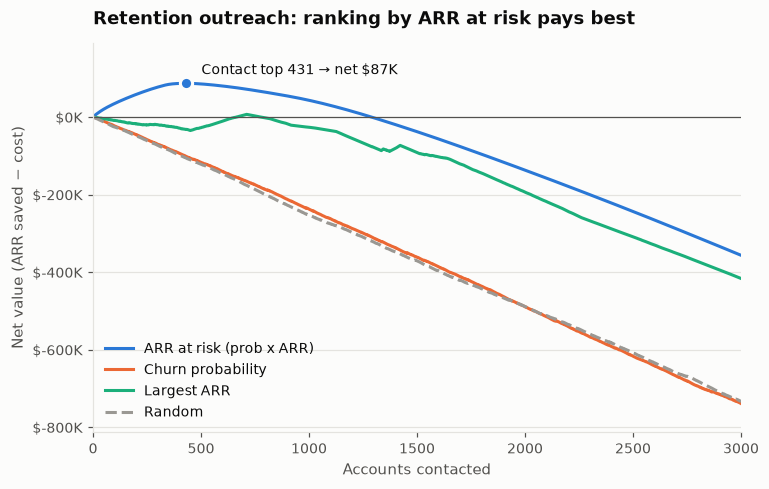

In [4]:
fig, ax = plt.subplots(figsize=(7.6, 4.6))
styles = [("ARR at risk (prob x ARR)", charts.SERIES[0], "-"), ("Churn probability", charts.SERIES[1], "-"),
          ("Largest ARR", charts.SERIES[2], "-"), ("Random", charts.REFERENCE, "--")]
for name, color, ls in styles:
    s = curve[curve["strategy"] == name]
    ax.plot(s["accounts_contacted"], s["net_value"], color=color, ls=ls, label=name)
best = plan[plan["strategy"] == "ARR at risk (prob x ARR)"].iloc[0]
ax.plot(best["accounts_contacted"], best["net_value"], "o", color=charts.SERIES[0], ms=8,
        markeredgecolor=charts.C["surface"], markeredgewidth=2)
ax.annotate(f"Contact top {best['accounts_contacted']:,.0f} → net ${best['net_value'] / 1e3:,.0f}K",
            (best["accounts_contacted"], best["net_value"]), xytext=(10, 6), textcoords="offset points", fontsize=9)
ax.axhline(0, color=charts.C["text_muted"], lw=0.8)
charts.money(ax, unit="K")
ax.set_xlim(0, 3000)
ax.set_ylim(bottom=min(-150_000, curve[curve["accounts_contacted"] <= 3000]["net_value"].min() * 1.1))
ax.set(xlabel="Accounts contacted")
ax.set_ylabel("Net value (ARR saved − cost)")
ax.set_title("Retention outreach: ranking by ARR at risk pays best")
ax.legend(loc="lower left")
charts.save(fig, "retention_roi.png"); plt.show()

In [5]:
sens = retention.sensitivity(risk)
print("Optimal plan (ranking by ARR at risk) under different assumptions:")
print(sens.pivot(index="save_rate", columns="cost_per_account", values="accounts_to_contact").to_string())
print()
print(sens.pivot(index="save_rate", columns="cost_per_account", values="net_value").round(0).to_string())

Optimal plan (ranking by ARR at risk) under different assumptions:
cost_per_account   200  400  800
save_rate                       
0.10               347    1    1
0.15               617   97    1
0.25              1765  431   24
0.35              3365  963  281

cost_per_account       200       400      800
save_rate                                    
0.10               19708.0      49.0   -351.0
0.15               72045.0    5000.0   -127.0
0.25              263926.0   87025.0   1441.0
0.35              590001.0  220714.0  36377.0


In [6]:
n_target = int(best["accounts_contacted"])
target_list = risk.sort_values("revenue_risk", ascending=False).head(n_target).assign(
    expected_arr_saved=lambda d: config.SAVE_RATE * d["revenue_risk"])
print(f"Target list: {n_target} accounts, ${target_list['arr'].sum():,.0f} ARR, "
      f"${target_list['revenue_risk'].sum():,.0f} at risk")
print(target_list[["customer_id", "segment", "plan_type", "arr", "churn_probability", "reason_1", "reason_2"]]
      .head(10).round(3).to_string(index=False))

curve_sampled = curve[(curve["accounts_contacted"] % 25 == 0) | (curve["accounts_contacted"] == 1)]
for name, df in {"gold_retention_curve": curve_sampled, "gold_retention_plan": plan,
                 "gold_retention_sensitivity": sens, "gold_retention_target_list": target_list}.items():
    spark_utils.write_table(spark, df, name)
    spark_utils.export_csv(spark, name)
print("Retention tables written and exported to data/gold/")

Target list: 431 accounts, $5,314,739 ARR, $1,037,698 at risk
 customer_id    segment  plan_type      arr  churn_probability                   reason_1                reason_2
        6014        SMB Enterprise 10479.24              0.428 Annual renewal in 2 months  Logins at 29% of usual
        6239        SMB Enterprise 11988.00              0.324     Logins at 36% of usual Month-to-month contract
        5057        SMB Enterprise 11988.00              0.313     Logins at 18% of usual Month-to-month contract
        1812        SMB Enterprise 13041.72              0.277     Logins at 46% of usual Month-to-month contract
        5866 Mid-Market Enterprise 11988.00              0.300     Renewal due next month  Logins at 40% of usual
        1070        SMB Enterprise 13955.40              0.257    Month-to-month contract  Logins at 55% of usual
        6823        SMB Enterprise 11988.00              0.297     Logins at 41% of usual Month-to-month contract
        2028        SMB En

Retention tables written and exported to data/gold/
